# Pair 3: Virtual hotel tours from phone video

**COMP8410 Assignment 1. Arnob Deb, 60841338.**

A large online travel platform wants hotels to offer virtual tours made from ordinary phone video. This
notebook compares two ways of building a 3D scene from the same frames, and holds all the code for this pair.

| Role | Model | Source of the method |
| --- | --- | --- |
| Platform A | Nerfacto | Tancik et al. (2023), Nerfstudio |
| Platform B | Splatfacto | Nerfstudio's version of 3D Gaussian Splatting, Kerbl et al. (2023) |
| Baseline | Nearest frame | Shows the closest training frame, with no 3D model |

**How to use it.** Run the cells from top to bottom.

- **With the saved results:** if the `results` folder holds all 12 rows, the notebook shows them and skips
  training. This needs only normal Python packages, and no Docker or GPU.
- **To repeat the whole experiment:** rename or remove the `results` and `processed` folders, then run the
  cells again. It takes several hours on an RTX 4060 Ti, and finished models are skipped if a run stops.

**What a full repeat needs:**

| Need | Why |
| --- | --- |
| NVIDIA GPU with at least 8 GB | Training runs on the GPU |
| Docker, with GPU access | Nerfstudio runs in its official Docker image, which holds COLMAP, ffmpeg and CUDA |
| `videos` folder beside this notebook | The phone videos are this pair's data, as `.mp4` or `.mov` files |

On Windows, install WSL with `wsl --install`, restart, then install and open Docker Desktop. The first run
downloads the Nerfstudio image, which is large.

## Settings

Everything you may want to change is in this cell. A quick run trains one scene for 300 steps to prove the
setup works. Its numbers must not be reported, so it saves them in a separate `results_quick` folder.

In [3]:
import csv
import random
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as ShowImage, Video, display
from PIL import Image, ImageDraw

# True runs any steps that aren't finished yet. Finished steps are always skipped.
RUN_PIPELINE = True

# True trains one scene for 300 steps. Don't report those numbers.
QUICK = False

# Set this to True only after both rating rounds are finished.
RATINGS_DONE = False

# The official image, which holds Nerfstudio, COLMAP, ffmpeg and a matching CUDA version.
IMAGE = "ghcr.io/nerfstudio-project/nerfstudio:latest"

# All files are found relative to this notebook's folder.
HERE = Path.cwd()
VIDEOS = HERE / "videos"
RESULTS_DIR = HERE / ("results_quick" if QUICK else "results")
print(f"Using the files in {HERE}")

Using the files in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair3_virtual_tours


## 1. Code that runs inside the container

Nerfstudio's Windows install is fragile and needs Visual Studio, so training runs inside the official Docker
image. The four cells below save the code that the container runs. Running them writes these `.py` files beside
the notebook, so the notebook is the only source of this code.

### Preparing the scenes

This turns each phone video into frames, works out where the camera was for each frame, and writes the train
and test lists. It also handles two problems found during this evaluation: COLMAP running out of memory on 4K
video, and Nerfstudio reading a tiny piece of a split reconstruction.

In [4]:
%%writefile prepare_scenes.py
"""
prepare_scenes.py - Turns each phone video into a dataset. Run it inside the container.

    python prepare_scenes.py

3D models need to know where the camera was for every picture. ns-process-data takes
evenly spaced frames from a video, and COLMAP then works out each camera position from
matching points between frames.

COLMAP can split a video into separate pieces, called models, when it can't link one
part of the video to the next. Nerfstudio always reads the first piece, even if that
piece is tiny. This file picks the largest piece instead. If that still leaves too many
frames unplaced, it tries once more with a slower matching method.

This file then writes two dataset files for each scene. Both test on exactly the same
held-out frames, so their scores can be compared fairly:

    full.json       Trains on all the remaining frames.
    reduced.json    Trains on half of them, which simulates a quicker hotel filming visit.
"""

import json
import shutil
import struct
import subprocess
from pathlib import Path
from typing import Optional

HERE = Path(__file__).resolve().parent
VIDEOS = HERE / "videos"
PROCESSED = HERE / "processed"

# 150 frames keeps processing short and fits an 8 GB GPU.
FRAMES_TARGET = 150

# Every 8th frame is held out for testing, a common choice for this kind of benchmark.
TEST_EVERY = 8

# Phone videos are often 4K. COLMAP ran out of memory on 4K frames, so each video is
# first reduced to this length on its long side. The models use half-size images in
# any case, so this doesn't change what they train on by much.
LONG_SIDE_PIXELS = 1920

# Below this share of matched frames, the camera positions are unreliable.
MINIMUM_MATCHED_SHARE = 0.8

# Sequential matching compares each frame with the frames near it in the video, which is
# quick. Exhaustive matching compares every frame with every other frame, so it can link
# parts of a video that are far apart in time, but it takes several times longer.
FIRST_MATCHING_METHOD = "sequential"
RETRY_MATCHING_METHOD = "exhaustive"

# This file records the method a scene ended up with, once the retry has been tried.
# Its presence also stops the slow retry from running again on the next run.
MATCHING_RECORD = "matching_used.txt"


def resize_video(video: Path) -> Path:
    """Save a smaller copy of the video, keeping its shape, and return the copy's path."""
    resized = PROCESSED / "_resized" / f"{video.stem}.mp4"
    if resized.exists():
        return resized
    resized.parent.mkdir(parents=True, exist_ok=True)
    # The long side becomes LONG_SIDE_PIXELS, whether the video is upright or sideways.
    # -2 keeps the shape and gives an even number, which video files need.
    size = f"scale='if(gt(iw,ih),{LONG_SIDE_PIXELS},-2)':'if(gt(iw,ih),-2,{LONG_SIDE_PIXELS})'"
    temporary = resized.with_suffix(".partial.mp4")
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(video), "-vf", size, "-crf", "18", "-preset", "veryfast", "-an", str(temporary)],
        check=True,
    )
    temporary.rename(resized)  # Only a finished file gets the final name.
    return resized


def run_colmap(video: Path, output: Path, method: str) -> None:
    """Extract frames from a video and estimate the camera positions."""
    subprocess.run(
        [
            "ns-process-data", "video",
            "--data", str(resize_video(video)),
            "--output-dir", str(output),
            "--num-frames-target", str(FRAMES_TARGET),
            "--matching-method", method,
            # COLMAP's GPU mode needs a display, which the container doesn't have.
            "--no-gpu",
        ],
        check=True,
    )


def registered_images(model: Path) -> int:
    """Return how many frames a COLMAP model placed."""
    # images.bin starts with this count, stored as an 8-byte whole number.
    with (model / "images.bin").open("rb") as file:
        return struct.unpack("<Q", file.read(8))[0]


def largest_model(output: Path) -> Optional[Path]:
    """Return the COLMAP model that placed the most frames, or None if there are none."""
    sparse = output / "colmap" / "sparse"
    if not sparse.exists():
        return None
    # Sorting by name means a tie always gives the same answer.
    models = sorted(folder for folder in sparse.iterdir() if (folder / "images.bin").exists())
    return max(models, key=registered_images, default=None)


def frames_in_dataset(output: Path) -> int:
    """Return how many frames the dataset file holds, or 0 if there is no such file."""
    transforms = output / "transforms.json"
    return len(json.loads(transforms.read_text())["frames"]) if transforms.exists() else 0


def matched_share(output: Path) -> float:
    """Return the share of extracted frames that have a camera position."""
    # Frames that COLMAP couldn't place are missing from transforms.json.
    return frames_in_dataset(output) / len(list((output / "images").glob("*")))


def use_largest_model(output: Path) -> None:
    """Rebuild the dataset from the largest COLMAP model, if it isn't already in use."""
    model = largest_model(output)
    if model is None or registered_images(model) == frames_in_dataset(output):
        return
    print(f"{output.name}: using {model.name}, which placed {registered_images(model)} frames")

    # Nerfstudio's last COLMAP step sharpens the lens settings of model 0 only, so the
    # chosen model gets the same step here. Otherwise it would be treated differently.
    refine = subprocess.run(
        [
            "colmap", "bundle_adjuster",
            "--input_path", str(model),
            "--output_path", str(model),
            "--BundleAdjustment.refine_principal_point", "1",
        ],
        capture_output=True,  # COLMAP prints a lot, so it only shows if something fails.
        text=True,
    )
    if refine.returncode != 0:
        raise SystemExit(refine.stderr[-2000:])

    # This writes transforms.json and sparse_pc.ply again from the chosen model, without
    # repeating COLMAP. Splatfacto starts from the points in sparse_pc.ply.
    subprocess.run(
        [
            "ns-process-data", "images",
            "--data", str(output / "images"),
            "--output-dir", str(output),
            "--skip-colmap",
            "--skip-image-processing",
            "--colmap-model-path", str(model.relative_to(output)),
        ],
        check=True,
    )


def retry_matching(video: Path, output: Path) -> None:
    """Run COLMAP again with slower matching, and keep whichever result placed more."""
    retry = output.with_name(f"{output.name}_retry")
    # Remove anything left by an earlier retry that stopped partway.
    if retry.exists():
        shutil.rmtree(retry)
    run_colmap(video, retry, RETRY_MATCHING_METHOD)
    use_largest_model(retry)

    # The first result stays in place until the retry has been shown to be better.
    if matched_share(retry) > matched_share(output):
        shutil.rmtree(output)
        retry.rename(output)
        (output / MATCHING_RECORD).write_text(RETRY_MATCHING_METHOD)
    else:
        shutil.rmtree(retry)
        (output / MATCHING_RECORD).write_text(FIRST_MATCHING_METHOD)


def process_video(video: Path, output: Path) -> None:
    """Make the dataset for one video, doing only the steps that aren't already done."""
    if (output / "transforms.json").exists():
        print(f"{video.stem}: COLMAP has already run")
    else:
        # Remove anything left by an earlier run that stopped partway.
        if output.exists():
            shutil.rmtree(output)
        run_colmap(video, output, FIRST_MATCHING_METHOD)

    use_largest_model(output)

    if matched_share(output) < MINIMUM_MATCHED_SHARE and not (output / MATCHING_RECORD).exists():
        print(f"{video.stem}: {matched_share(output):.0%} of frames placed, so trying {RETRY_MATCHING_METHOD} matching")
        retry_matching(video, output)

    if frames_in_dataset(output) == 0:
        raise SystemExit(f"COLMAP couldn't place any frames in {video.stem}. Film it again more slowly.")


def write_split(meta: dict, output: Path, name: str, train: list[str], test: list[str]) -> None:
    """Save a copy of the dataset file that names its own train and test frames."""
    split = dict(meta)
    split["train_filenames"] = train
    split["val_filenames"] = test  # Used for progress checks during training.
    split["test_filenames"] = test  # Used for the final scores.
    (output / f"{name}.json").write_text(json.dumps(split, indent=2))


def main() -> None:
    videos = sorted(path for path in VIDEOS.iterdir() if path.suffix.lower() in {".mp4", ".mov"})
    if not videos:
        raise SystemExit(f"No videos found. Put your .mp4 or .mov files in {VIDEOS}")

    summary = []
    for video in videos:
        output = PROCESSED / video.stem
        process_video(video, output)

        meta = json.loads((output / "transforms.json").read_text())
        names = sorted(frame["file_path"] for frame in meta["frames"])
        share = matched_share(output)
        record = output / MATCHING_RECORD

        test = names[::TEST_EVERY]
        train = [name for name in names if name not in test]
        write_split(meta, output, "full", train, test)
        write_split(meta, output, "reduced", train[::2], test)

        row = {
            "scene": video.stem,
            "frames_extracted": len(list((output / "images").glob("*"))),
            "frames_matched": len(names),
            "matched_share": round(share, 3),
            "matching": record.read_text() if record.exists() else FIRST_MATCHING_METHOD,
            "train_frames_full": len(train),
            "train_frames_reduced": len(train[::2]),
            "test_frames": len(test),
        }
        summary.append(row)
        print(row)
        if share < MINIMUM_MATCHED_SHARE:
            print(f"WARNING: only {share:.0%} of frames matched in {video.stem}. Film it again more slowly.")

    (PROCESSED / "scene_summary.json").write_text(json.dumps(summary, indent=2))


if __name__ == "__main__":
    main()

Writing prepare_scenes.py


### Training and testing

This trains and tests each model on each scene, and records the scores and costs.

In [5]:
%%writefile run_evaluation.py
"""
run_evaluation.py - Trains and tests each 3D model on each scene. Run it in the container.

Full run:             python run_evaluation.py
Short setup check:    python run_evaluation.py --quick

The two platforms are compared on the same scenes, images, test views and training
length. A full run trains 8 models, which takes hours, so leave it running. After each
model it saves a result, and if it stops, the same command continues from there.
A --quick run saves to results_quick, and those numbers must not be reported.
"""

import argparse
import csv
import json
import subprocess
import threading
import time
from importlib import metadata
from pathlib import Path

HERE = Path(__file__).resolve().parent
PROCESSED = HERE / "processed"

# Half-size images keep both models within an 8 GB GPU. Both use the same size.
DOWNSCALE = 2

# A fixed seed makes a run repeatable, as far as GPU calculations allow.
SEED = 42

# Options that apply to one model only.
MODEL_OPTIONS = {
    "nerfacto": [
        # By default, Nerfacto adjusts training cameras as it learns but can't adjust
        # test cameras, which lowers its test scores unfairly. Splatfacto's default is
        # already off, so this makes the comparison equal.
        "--pipeline.model.camera-optimizer.mode", "off",
    ],
    "splatfacto": [
        # Keeps the training images in normal memory, which leaves more GPU memory.
        "--pipeline.datamanager.cache-images", "cpu",
    ],
}

# Options for the data reader, which must come last on the command line.
DATA_OPTIONS = {
    "nerfacto": [],
    # Splatfacto starts from COLMAP's 3D points. This flag is stated directly, because
    # naming nerfstudio-data on the command line resets the method's own setting.
    "splatfacto": ["--load-3D-points", "True"],
}

COLUMNS = [
    "scene", "model", "frames", "status", "train_frames", "test_frames", "iterations",
    "psnr", "ssim", "lpips", "render_fps", "train_minutes", "peak_gpu_gb", "storage_mb",
]


class MemoryWatcher(threading.Thread):
    """Reads GPU memory every 2 seconds during training and keeps the highest value."""

    def __init__(self):
        super().__init__(daemon=True)
        self.peak_mb = None
        self.finished = threading.Event()

    def run(self):
        while not self.finished.wait(2):
            result = subprocess.run(
                ["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                capture_output=True, text=True,
            )
            try:
                used = float(result.stdout.strip().splitlines()[0])
            except (ValueError, IndexError):
                continue  # A missed reading doesn't matter, so try again next time.
            self.peak_mb = max(self.peak_mb or 0, used)


def folder_size_mb(folder: Path) -> float:
    return sum(path.stat().st_size for path in folder.rglob("*") if path.is_file()) / 1024**2


def train_command(model: str, data_file: Path, experiment: str, outputs: Path, iterations: int) -> list[str]:
    """Build the ns-train command. The fixed folder names let later steps find the model."""
    return [
        "ns-train", model,
        "--data", str(data_file),
        "--output-dir", str(outputs),
        "--experiment-name", experiment,
        "--timestamp", "run",
        "--max-num-iterations", str(iterations),
        "--machine.seed", str(SEED),
        "--vis", "tensorboard",  # No browser window, so the run finishes by itself.
        # Skips slow progress reports, because the final test below gives the scores.
        "--steps-per-eval-all-images", "1000000",
        *MODEL_OPTIONS[model],
        "nerfstudio-data",
        "--downscale-factor", str(DOWNSCALE),
        *DATA_OPTIONS[model],
    ]


def run_logged(command: list[str], log_path: Path) -> bool:
    """Run a command, save its output to a log, and return True if it succeeded."""
    with log_path.open("a", encoding="utf-8") as log:
        log.write("\n$ " + " ".join(command) + "\n")
        log.flush()
        return subprocess.run(command, stdout=log, stderr=subprocess.STDOUT).returncode == 0


def run_model(scene: Path, model: str, frames: str, iterations: int, outputs: Path, results: Path) -> dict:
    """Train one model, test it, and return one row of results."""
    experiment = f"{scene.name}_{frames}"
    run_name = f"{scene.name}__{model}__{frames}"
    logs = results / "logs"
    logs.mkdir(exist_ok=True)
    log_path = logs / f"{run_name}.log"

    data_file = scene / f"{frames}.json"
    meta = json.loads(data_file.read_text())
    row = {
        "scene": scene.name, "model": model, "frames": frames, "status": "failed",
        "train_frames": len(meta["train_filenames"]), "test_frames": len(meta["test_filenames"]),
        "iterations": iterations,
    }

    # 1. Train, watching GPU memory and time.
    print(f"Training {run_name}. Follow progress in {log_path}")
    watcher = MemoryWatcher()
    watcher.start()
    started = time.perf_counter()
    trained = run_logged(train_command(model, data_file, experiment, outputs, iterations), log_path)
    row["train_minutes"] = round((time.perf_counter() - started) / 60, 2)
    watcher.finished.set()
    watcher.join()
    row["peak_gpu_gb"] = round(watcher.peak_mb / 1024, 2) if watcher.peak_mb else None
    if not trained:
        print(f"FAILED: {run_name}. See the end of {log_path}")
        return row

    run_dir = outputs / experiment / model / "run"
    config = run_dir / "config.yml"
    row["storage_mb"] = round(folder_size_mb(run_dir / "nerfstudio_models"), 1)

    # 2. Score the held-out test views, and save the images for visual checks.
    eval_file = results / "evals" / f"{run_name}.json"
    eval_file.parent.mkdir(exist_ok=True)
    if not run_logged(
        ["ns-eval", "--load-config", str(config), "--output-path", str(eval_file), "--render-output-path", str(results / "renders" / run_name)],
        log_path,
    ):
        print(f"FAILED during testing: {run_name}. See the end of {log_path}")
        return row
    scores = json.loads(eval_file.read_text())["results"]
    row.update(psnr=scores["psnr"], ssim=scores["ssim"], lpips=scores["lpips"], status="done")

    # 3. Measure drawing speed. A failure here keeps the scores and leaves this blank.
    speed = subprocess.run(["python", str(HERE / "measure_speed.py"), str(config)], capture_output=True, text=True)
    try:
        row["render_fps"] = json.loads(speed.stdout.strip().splitlines()[-1])["render_fps"]
    except (ValueError, IndexError, KeyError):
        print(f"Couldn't measure drawing speed for {run_name}")
        with log_path.open("a", encoding="utf-8") as log:
            log.write(speed.stdout + speed.stderr)

    # 4. Make a short walkthrough video for the presentation, from the full data only.
    if frames == "full":
        video = results / "videos" / f"{run_name}.mp4"
        video.parent.mkdir(exist_ok=True)
        run_logged(
            ["ns-render", "interpolate", "--load-config", str(config), "--output-path", str(video), "--pose-source", "eval", "--interpolation-steps", "6", "--frame-rate", "24"],
            log_path,
        )
    return row


def run_baseline(scene: Path, frames: str, results: Path) -> dict:
    """Score the nearest-frame baseline, which needs no training."""
    run_name = f"{scene.name}__nearest-frame__{frames}"
    output = results / "evals" / f"{run_name}.json"
    finished = subprocess.run(["python", str(HERE / "baseline_nearest_frame.py"), str(scene), frames, "--output", str(output)])
    meta = json.loads((scene / f"{frames}.json").read_text())
    row = {
        "scene": scene.name, "model": "nearest-frame", "frames": frames, "status": "failed",
        "train_frames": len(meta["train_filenames"]), "test_frames": len(meta["test_filenames"]),
    }
    if finished.returncode == 0:
        row.update(json.loads(output.read_text()), status="done")
    return row


def save_table(rows: list[dict], path: Path) -> None:
    """Rewrite the results table, which is safe to do after every run."""
    with path.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=COLUMNS, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def main() -> None:
    parser = argparse.ArgumentParser(description="Pair 3 virtual tour evaluation")
    # Both models use Nerfstudio's standard training length.
    parser.add_argument("--iterations", type=int, default=30000, help="training steps per model")
    parser.add_argument("--quick", action="store_true", help="short setup check, not for reporting")
    args = parser.parse_args()

    scenes = sorted(path for path in PROCESSED.iterdir() if (path / "full.json").exists())
    if not scenes:
        raise SystemExit("No prepared scenes found. Run prepare_scenes.py first.")

    frame_levels = ["full", "reduced"]
    iterations = args.iterations
    if args.quick:
        scenes, frame_levels, iterations = scenes[:1], ["full"], 300

    results = HERE / ("results_quick" if args.quick else "results")
    outputs = HERE / ("outputs_quick" if args.quick else "outputs")
    results.mkdir(exist_ok=True)
    table = results / "metrics.csv"

    # Earlier finished runs are kept. Failed runs are tried again.
    rows = []
    if table.exists():
        with table.open(encoding="utf-8") as file:
            rows = [row for row in csv.DictReader(file) if row["status"] == "done"]
    finished = {(row["scene"], row["model"], row["frames"]) for row in rows}

    for scene in scenes:
        for frames in frame_levels:
            if (scene.name, "nearest-frame", frames) not in finished:
                (results / "evals").mkdir(exist_ok=True)
                rows.append(run_baseline(scene, frames, results))
                save_table(rows, table)
            for model in MODEL_OPTIONS:
                if (scene.name, model, frames) in finished:
                    print(f"Already finished: {scene.name} {model} {frames}")
                    continue
                rows.append(run_model(scene, model, frames, iterations, outputs, results))
                save_table(rows, table)

    # Record the exact software versions for the report.
    # The version comes from Python itself, because the container has no pip command.
    try:
        nerfstudio_version = metadata.version("nerfstudio")
    except metadata.PackageNotFoundError:
        nerfstudio_version = None  # A missing version shouldn't stop a finished run.
    colmap = subprocess.run(["colmap", "-h"], capture_output=True, text=True).stdout.splitlines()[:2]
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
    environment = {
        "nerfstudio": nerfstudio_version,
        "colmap": colmap,
        "gpu": gpu,
        "settings": {"iterations": iterations, "downscale": DOWNSCALE, "seed": SEED, "model_options": MODEL_OPTIONS, "data_options": DATA_OPTIONS},
    }
    (results / "environment.json").write_text(json.dumps(environment, indent=2))

    failed = [row for row in rows if row["status"] != "done"]
    print(f"\nFinished. Results are in {table}. Failed runs: {len(failed)}")


if __name__ == "__main__":
    main()

Writing run_evaluation.py


### The nearest-frame baseline

If a 3D model can't beat the closest existing photo, the extra cost of 3D isn't justified.

In [6]:
%%writefile baseline_nearest_frame.py
"""
baseline_nearest_frame.py - The simple baseline for Pair 3.

A hotel could skip 3D entirely and show the closest photo it already has. For each test
view, this file finds the nearest training frame and scores it against the real view,
using the same image metrics Nerfstudio uses. If a 3D model can't beat this, the extra
cost of 3D isn't justified.

Run it inside the container:   python baseline_nearest_frame.py processed/place1 full
"""

import argparse
import json
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torchmetrics.functional import structural_similarity_index_measure
from torchmetrics.image import PeakSignalNoiseRatio
from torchmetrics.image.lpip import LearnedPerceptualImagePatchSimilarity

# Each model's images are half size. The baseline must use the same size.
DOWNSCALE = 2


def camera_position_and_direction(frame: dict) -> tuple[np.ndarray, np.ndarray]:
    """Read one camera's location and viewing direction from its 4x4 matrix."""
    matrix = np.array(frame["transform_matrix"])
    # In this format, the camera looks along the negative third column.
    return matrix[:3, 3], -matrix[:3, 2]


def nearest_train_frame(test_frame: dict, train_frames: list[dict], position_scale: float) -> dict:
    """
    Pick the training frame with the closest position and viewing direction.

    Position and angle have different units, so each is scaled before they are added.
    One typical step between frames counts the same as a 10 degree turn.
    """
    position, direction = camera_position_and_direction(test_frame)
    best_frame, best_score = None, float("inf")
    for frame in train_frames:
        other_position, other_direction = camera_position_and_direction(frame)
        distance = np.linalg.norm(position - other_position) / position_scale
        angle = np.degrees(np.arccos(np.clip(direction @ other_direction, -1.0, 1.0))) / 10.0
        if distance + angle < best_score:
            best_frame, best_score = frame, distance + angle
    return best_frame


def load_image(scene: Path, frame: dict, device: torch.device) -> torch.Tensor:
    """Load a half-size image as a [1, 3, height, width] tensor with values from 0 to 1."""
    path = scene / f"images_{DOWNSCALE}" / Path(frame["file_path"]).name
    pixels = np.asarray(Image.open(path).convert("RGB"), dtype=np.float32) / 255.0
    return torch.from_numpy(pixels).permute(2, 0, 1)[None].to(device)


def main() -> None:
    parser = argparse.ArgumentParser(description="Nearest-frame baseline")
    parser.add_argument("scene", type=Path, help="processed scene folder")
    parser.add_argument("frames", choices=["full", "reduced"], help="which training set to use")
    parser.add_argument("--output", type=Path, required=True, help="result JSON file")
    args = parser.parse_args()

    meta = json.loads((args.scene / f"{args.frames}.json").read_text())
    by_name = {frame["file_path"]: frame for frame in meta["frames"]}
    train = [by_name[name] for name in meta["train_filenames"]]
    test = [by_name[name] for name in meta["test_filenames"]]

    # The typical gap between neighbouring training cameras sets the position scale.
    positions = np.array([camera_position_and_direction(frame)[0] for frame in train])
    steps = np.linalg.norm(np.diff(positions, axis=0), axis=1)
    position_scale = float(np.median(steps)) or 1.0

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # These match the metric settings in Nerfstudio's model code.
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    lpips = LearnedPerceptualImagePatchSimilarity(normalize=True).to(device)

    scores = {"psnr": [], "ssim": [], "lpips": []}
    with torch.no_grad():
        for frame in test:
            truth = load_image(args.scene, frame, device)
            shown = load_image(args.scene, nearest_train_frame(frame, train, position_scale), device)
            scores["psnr"].append(float(psnr(truth, shown)))
            scores["ssim"].append(float(structural_similarity_index_measure(truth, shown)))
            scores["lpips"].append(float(lpips(truth, shown)))

    result = {key: float(np.mean(values)) for key, values in scores.items()}
    args.output.parent.mkdir(parents=True, exist_ok=True)
    args.output.write_text(json.dumps(result, indent=2))
    print(result)


if __name__ == "__main__":
    main()

Writing baseline_nearest_frame.py


### Drawing speed

This times the drawing step alone, because a virtual tour must respond smoothly.

In [7]:
%%writefile measure_speed.py
"""
measure_speed.py - Measures how fast a trained model draws new views.

A virtual tour must respond smoothly, so this is a business measure. ns-eval also reports
frames per second, but its timer includes the image metrics and saving files, which hides
the speed of a very fast model. This file times the drawing step alone.

run_evaluation.py calls it. To run it yourself, inside the container:
    python measure_speed.py outputs/place1_full/splatfacto/run/config.yml
"""

import json
import sys
import time
from pathlib import Path

import torch
from nerfstudio.utils.eval_utils import eval_setup


def main() -> None:
    _, pipeline, _, _ = eval_setup(Path(sys.argv[1]), test_mode="test")
    timings = []
    with torch.no_grad():
        for index, (camera, _) in enumerate(pipeline.datamanager.fixed_indices_eval_dataloader):
            torch.cuda.synchronize()  # Wait for earlier GPU work, so the timer is exact.
            started = time.perf_counter()
            pipeline.model.get_outputs_for_camera(camera=camera)
            torch.cuda.synchronize()
            # The first view includes one-off setup work, so it isn't counted.
            if index > 0:
                timings.append(time.perf_counter() - started)

    # run_evaluation.py reads this last line.
    print(json.dumps({"render_fps": len(timings) / sum(timings)}))


if __name__ == "__main__":
    main()

Writing measure_speed.py


## 2. Run the experiment

This cell starts the container for each step. It shows the output as it arrives, and stops with a clear message
if something is missing. If all the results already exist, it skips the container, so Docker isn't needed.

In [8]:
def run_in_container(*command: str) -> None:
    """Run one command in the Nerfstudio container, showing its output as it arrives."""
    docker = [
        "docker", "run",
        "--gpus", "all",        # Lets the container use the NVIDIA GPU.
        "--rm",                 # Removes the container afterwards. Files stay in this folder.
        "--shm-size=12gb",      # Raises Docker's small shared memory limit, as its docs advise.
        "-v", f"{HERE}:/workspace",             # Shows this folder as /workspace.
        "-v", "nerfstudio-cache:/root/.cache",  # Keeps downloaded weights between runs.
        "-w", "/workspace",     # Starts in that folder.
        IMAGE, *command,
    ]
    process = subprocess.Popen(docker, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", errors="replace")
    for line in process.stdout:
        print(line, end="")
    if process.wait() != 0:
        raise SystemExit(f"This step failed in the container: {' '.join(command)}")


def phone_videos() -> list[Path]:
    """List the phone videos, which are this pair's data."""
    if not VIDEOS.exists():
        return []
    return sorted(path for path in VIDEOS.iterdir() if path.suffix.lower() in {".mp4", ".mov"})


def evaluation_finished() -> bool:
    """Return True when every expected result is already saved."""
    table = RESULTS_DIR / "metrics.csv"
    if not table.exists():
        return False
    finished = (pd.read_csv(table)["status"] == "done").sum()
    # Each scene has 2 frame levels and 3 methods. A quick run covers one scene at one level.
    return finished >= (3 if QUICK else 6 * max(len(phone_videos()), 2))


def check_docker() -> None:
    """Stop with a clear message if the experiment can't start."""
    if not phone_videos():
        raise SystemExit(f"No videos found. Put your .mp4 or .mov files in {VIDEOS}")
    if shutil.which("docker") is None or subprocess.run(["docker", "info"], capture_output=True).returncode != 0:
        raise SystemExit("Docker isn't running. Install Docker Desktop, open it, then run this cell again.")

In [9]:
if evaluation_finished():
    print(f"All results are already saved in {RESULTS_DIR}, so the experiment is skipped.")
elif RUN_PIPELINE:
    check_docker()
    run_in_container("python", "prepare_scenes.py")
    run_in_container("python", "run_evaluation.py", *(["--quick"] if QUICK else []))
else:
    raise SystemExit("RUN_PIPELINE is False and some results are missing.")


== CUDA ==

CUDA Version 11.8.0

Container image Copyright (c) 2016-2023, NVIDIA CORPORATION & AFFILIATES. All rights reserved.

This container image and its contents are governed by the NVIDIA Deep Learning Container License.
By pulling and using the container, you accept the terms and conditions of this license:
https://developer.nvidia.com/ngc/nvidia-deep-learning-container-license

A copy of this license is made available in this container at /NGC-DL-CONTAINER-LICENSE for your convenience.

Number of frames in video: 1578
Extracting 158 frames in evenly spaced intervals
[04:43:33] 🎉 Done converting video to images.                                                 process_data_utils.py:227
[04:44:40] 🎉 Done extracting COLMAP features.                                                       colmap_utils.py:137
[04:46:55] 🎉 Done matching COLMAP features.                                                         colmap_utils.py:151
[04:52:23] 🎉 Done COLMAP bundle adjustment.               

## 3. Results

### Scene preparation

This shows how many frames COLMAP placed in each scene, and which matching method it needed.

In [10]:
summary_file = HERE / "processed" / "scene_summary.json"
if summary_file.exists():
    display(pd.read_json(summary_file))
else:
    print("The processed folder isn't here, so this table can't be shown.")

,scene,frames_extracted,frames_matched,matched_share,matching,train_frames_full,train_frames_reduced,test_frames
0,place1,158,158,1,sequential,138,69,20
1,place2,162,162,1,sequential,141,71,21


### Image quality and costs

PSNR, SSIM and LPIPS compare each drawn view with the real held-out frame. Week 8 calls this a verifiable task,
because a correct answer exists. Peak GPU memory covers the whole card.

In [11]:
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
display(metrics[metrics["status"] != "done"])

columns = ["scene", "frames", "model", "train_frames", "test_frames", "psnr", "ssim", "lpips"]
display(metrics[columns].round(3))

costs = metrics[metrics["model"] != "nearest-frame"]
display(costs[["scene", "frames", "model", "render_fps", "train_minutes", "peak_gpu_gb", "storage_mb"]].round(2))

,scene,model,frames,status,train_frames,test_frames,iterations,psnr,ssim,lpips,render_fps,train_minutes,peak_gpu_gb,storage_mb


,scene,frames,model,train_frames,test_frames,psnr,ssim,lpips
0,place1,full,nearest-frame,138,20,17.980,0.627,0.269
1,place1,full,nerfacto,138,20,27.474,0.953,0.061
2,place1,full,splatfacto,138,20,35.058,0.967,0.049
3,place1,reduced,nearest-frame,69,20,17.941,0.628,0.276
4,place1,reduced,nerfacto,69,20,26.893,0.951,0.062
5,place1,reduced,splatfacto,69,20,34.923,0.965,0.049
6,place2,full,nearest-frame,141,21,17.452,0.630,0.310
7,place2,full,nerfacto,141,21,26.283,0.954,0.064
8,place2,full,splatfacto,141,21,35.773,0.973,0.046
9,place2,reduced,nearest-frame,71,21,17.601,0.636,0.293


,scene,frames,model,render_fps,train_minutes,peak_gpu_gb,storage_mb
1,place1,full,nerfacto,0.79,17.51,4.56,167.8
2,place1,full,splatfacto,198.75,11.01,1.46,145.9
4,place1,reduced,nerfacto,0.79,17.34,4.55,167.8
5,place1,reduced,splatfacto,224.34,10.91,1.33,142.0
7,place2,full,nerfacto,0.79,17.71,4.56,167.8
8,place2,full,splatfacto,217.72,11.46,2.18,161.0
10,place2,reduced,nerfacto,0.79,17.67,4.56,167.8
11,place2,reduced,splatfacto,207.44,11.25,1.39,157.2


### Run settings

This records the software versions, the GPU and the settings of the run.

In [12]:
print((RESULTS_DIR / "environment.json").read_text())

{
  "nerfstudio": "1.1.5",
  "colmap": [
    "COLMAP 3.9.1 -- Structure-from-Motion and Multi-View Stereo",
    "(Commit e9903641 on 2024-01-08 with CUDA)"
  ],
  "gpu": "NVIDIA GeForce RTX 4060 Ti, 610.88",
  "settings": {
    "iterations": 30000,
    "downscale": 2,
    "seed": 42,
    "model_options": {
      "nerfacto": [
        "--pipeline.model.camera-optimizer.mode",
        "off"
      ],
      "splatfacto": [
        "--pipeline.datamanager.cache-images",
        "cpu"
      ]
    },
    "data_options": {
      "nerfacto": [],
      "splatfacto": [
        "--load-3D-points",
        "True"
      ]
    }
  }
}


## 4. Colour check

Phone cameras change brightness and colour as they move. Nerfacto learns a separate colour setting for each
training frame and uses their average on a test view, while Splatfacto has no such setting. A view with the right
shapes but slightly wrong brightness therefore loses a lot of PSNR, while SSIM and LPIPS change less.

This section reads the test views that `ns-eval` saved. Each saved image holds the real view on the left and the
model's view on the right. It scores each view twice:

- **Raw:** the same PSNR that the report uses.
- **Matched:** PSNR after fitting a brightness and contrast change to each colour.

The fit looks at the real view, which a real tour couldn't do, so the matched score is only a diagnosis. The raw
score stays the headline result. If the gap between the models shrinks a lot after matching, then colour explains
that part of the gap.

In [13]:
RENDERS = RESULTS_DIR / "renders"
COLOUR_FILE = RESULTS_DIR / "colour_check.csv"
MODELS = ["nerfacto", "splatfacto"]


def split_render_pixels(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Return the real view and the model's view, with values from 0 to 1."""
    combined = np.asarray(Image.open(path).convert("RGB"), dtype=np.float64) / 255
    middle = combined.shape[1] // 2
    return combined[:, :middle], combined[:, middle:]


def psnr(real: np.ndarray, drawn: np.ndarray) -> float:
    """Peak signal-to-noise ratio in decibels. Higher means closer to the real view."""
    return float(-10 * np.log10(np.mean((real - drawn) ** 2)))


def match_colour(real: np.ndarray, drawn: np.ndarray) -> np.ndarray:
    """Fit gain * drawn + offset to the real view, separately for red, green and blue."""
    matched = np.empty_like(drawn)
    for channel in range(3):
        gain, offset = np.polyfit(drawn[..., channel].ravel(), real[..., channel].ravel(), 1)
        matched[..., channel] = gain * drawn[..., channel] + offset
    return np.clip(matched, 0, 1)  # Images can't go below 0 or above 1.


def score_run(folder: Path) -> tuple[list[float], list[float]]:
    """Return each view's raw and colour-matched PSNR for one trained model."""
    raw, matched = [], []
    for path in sorted(folder.glob("eval_img_*.png")):
        real, drawn = split_render_pixels(path)
        raw.append(psnr(real, drawn))
        matched.append(psnr(real, match_colour(real, drawn)))
    return raw, matched

In [14]:
def run_colour_check() -> pd.DataFrame:
    """Compare the two models before and after colour matching."""
    rows = []
    scenes = sorted({path.name.split("__")[0] for path in RENDERS.glob("*__nerfacto__*")})
    for scene in scenes:
        for frames in ["full", "reduced"]:
            scores = {}
            for model in MODELS:
                folder = RENDERS / f"{scene}__{model}__{frames}"
                if folder.exists():
                    scores[model] = score_run(folder)
            if len(scores) < len(MODELS):
                continue  # Both models are needed for a comparison.

            raw_gap = np.array(scores["splatfacto"][0]) - np.array(scores["nerfacto"][0])
            matched_gap = np.array(scores["splatfacto"][1]) - np.array(scores["nerfacto"][1])
            rows.append(
                {
                    "scene": scene,
                    "frames": frames,
                    "test_views": len(raw_gap),
                    "nerfacto_raw": round(float(np.mean(scores["nerfacto"][0])), 2),
                    "splatfacto_raw": round(float(np.mean(scores["splatfacto"][0])), 2),
                    "nerfacto_matched": round(float(np.mean(scores["nerfacto"][1])), 2),
                    "splatfacto_matched": round(float(np.mean(scores["splatfacto"][1])), 2),
                    "raw_gap": round(float(np.mean(raw_gap)), 2),
                    "matched_gap": round(float(np.mean(matched_gap)), 2),
                    # How many views Splatfacto wins, because a mean can hide a few extremes.
                    "splatfacto_wins_raw": int(np.sum(raw_gap > 0)),
                    "splatfacto_wins_matched": int(np.sum(matched_gap > 0)),
                }
            )

    if not rows:
        raise SystemExit(f"No saved test views found in {RENDERS}. Run run_evaluation.py first.")
    with COLOUR_FILE.open("w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    return pd.DataFrame(rows)

In [15]:
display(run_colour_check())

,scene,frames,test_views,nerfacto_raw,splatfacto_raw,nerfacto_matched,splatfacto_matched,raw_gap,matched_gap,splatfacto_wins_raw,splatfacto_wins_matched
0,place1,full,20,27.47,35.03,33.40,35.65,7.56,2.25,20,17
1,place1,reduced,20,26.89,34.90,32.64,35.34,8.01,2.70,20,18
2,place2,full,21,26.28,35.75,33.80,36.22,9.47,2.43,21,17
3,place2,reduced,21,25.74,35.22,33.17,35.77,9.48,2.59,21,18


## 5. Charts

The charts read the saved results only. They are saved in `results/figures`.

In [16]:
# Each model keeps the same colour in every chart, so readers can follow it.
COLOURS = {"nerfacto": "#2a78d6", "splatfacto": "#eb6834", "nearest-frame": "#1baf7a"}


LABELS = {"nerfacto": "Nerfacto", "splatfacto": "Splatfacto", "nearest-frame": "Nearest frame baseline"}


TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"


plt.rcParams.update(
    {
        "font.size": 10,
        "text.color": TEXT,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
    }
)

In [17]:
def chart_quality(table: pd.DataFrame, out: Path) -> None:
    """Show the three image scores for every scene and amount of training data."""
    panels = [("psnr", "PSNR (higher is better)"), ("ssim", "SSIM (higher is better)"), ("lpips", "LPIPS (lower is better)")]
    conditions = sorted({(row.scene, row.frames) for row in table.itertuples()}, key=lambda item: (item[0], item[1] != "full"))
    models = [model for model in COLOURS if model in set(table["model"])]
    spacing = 0.7 / len(models)

    fig, axes = plt.subplots(1, 3, figsize=(11, 0.75 * len(conditions) + 1.4), sharey=True)
    for axis, (column, title) in zip(axes, panels):
        for index, model in enumerate(models):
            part = table[table["model"] == model].set_index(["scene", "frames"])
            for row, condition in enumerate(conditions):
                if condition in part.index:
                    axis.scatter(part.loc[condition, column], row - 0.35 + spacing * (index + 0.5), color=COLOURS[model], s=45, zorder=3, label=LABELS[model] if row == 0 else None)
        axis.set_title(title, loc="left", fontsize=10, color=TEXT)
        axis.grid(axis="x", color=GRID, linewidth=0.8)
        axis.set_axisbelow(True)
    axes[0].set_yticks(range(len(conditions)), [f"{scene}, {frames} frames" for scene, frames in conditions])
    axes[0].invert_yaxis()
    axes[2].legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.suptitle("Image quality on held-out test views", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(out / "fig1_quality.png")
    plt.close(fig)

In [18]:
def chart_costs(table: pd.DataFrame, out: Path) -> None:
    """Show what each model costs to train, store and display."""
    trained = table[table["model"] != "nearest-frame"]
    panels = [
        ("train_minutes", "Training time (minutes)"),
        ("render_fps", "Drawing speed (FPS, log scale)"),
        ("peak_gpu_gb", "Peak GPU memory in use (GB)"),
        ("storage_mb", "Saved model size (MB)"),
    ]
    models = [model for model in COLOURS if model in set(trained["model"])]
    fig, axes = plt.subplots(1, 4, figsize=(12, 2.4), sharey=True)
    for axis, (column, title) in zip(axes, panels):
        for row, model in enumerate(models):
            values = trained.loc[trained["model"] == model, column].dropna()
            axis.scatter(values, [row] * len(values), color=COLOURS[model], s=40, alpha=0.75, zorder=3)
        if column == "render_fps":
            axis.set_xscale("log")
        axis.set_title(title, loc="left", fontsize=9, color=TEXT)
        axis.grid(axis="x", color=GRID, linewidth=0.8)
        axis.set_axisbelow(True)
    axes[0].set_yticks(range(len(models)), [LABELS[model] for model in models])
    axes[0].set_ylim(len(models) - 0.5, -0.5)
    fig.suptitle("Cost of each model. Each dot is one run", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(out / "fig2_costs.png")
    plt.close(fig)

In [19]:
def chart_fewer_frames(table: pd.DataFrame, out: Path) -> None:
    """Show how quality changes with half the training frames, per scene."""
    if "reduced" not in set(table["frames"]):
        return  # A quick run has no reduced data.
    fig, axis = plt.subplots(figsize=(6.5, 3.8))
    for model in COLOURS:
        for index, (_, part) in enumerate(table[table["model"] == model].groupby("scene")):
            part = part.set_index("frames")
            axis.plot([0, 1], [part.loc["full", "psnr"], part.loc["reduced", "psnr"]], color=COLOURS[model], marker="o", linewidth=2, label=LABELS[model] if index == 0 else None)
    axis.set_xticks([0, 1], ["Full frames", "Half the frames"])
    axis.set_xlim(-0.2, 1.2)
    axis.set_ylabel("PSNR (dB)")
    axis.grid(axis="y", color=GRID, linewidth=0.8)
    axis.set_title("Effect of using half the frames. One line per scene", loc="left", fontsize=12, fontweight="bold")
    axis.legend(frameon=False, loc="center left", bbox_to_anchor=(1, 0.5))
    fig.savefig(out / "fig3_fewer_frames.png")
    plt.close(fig)

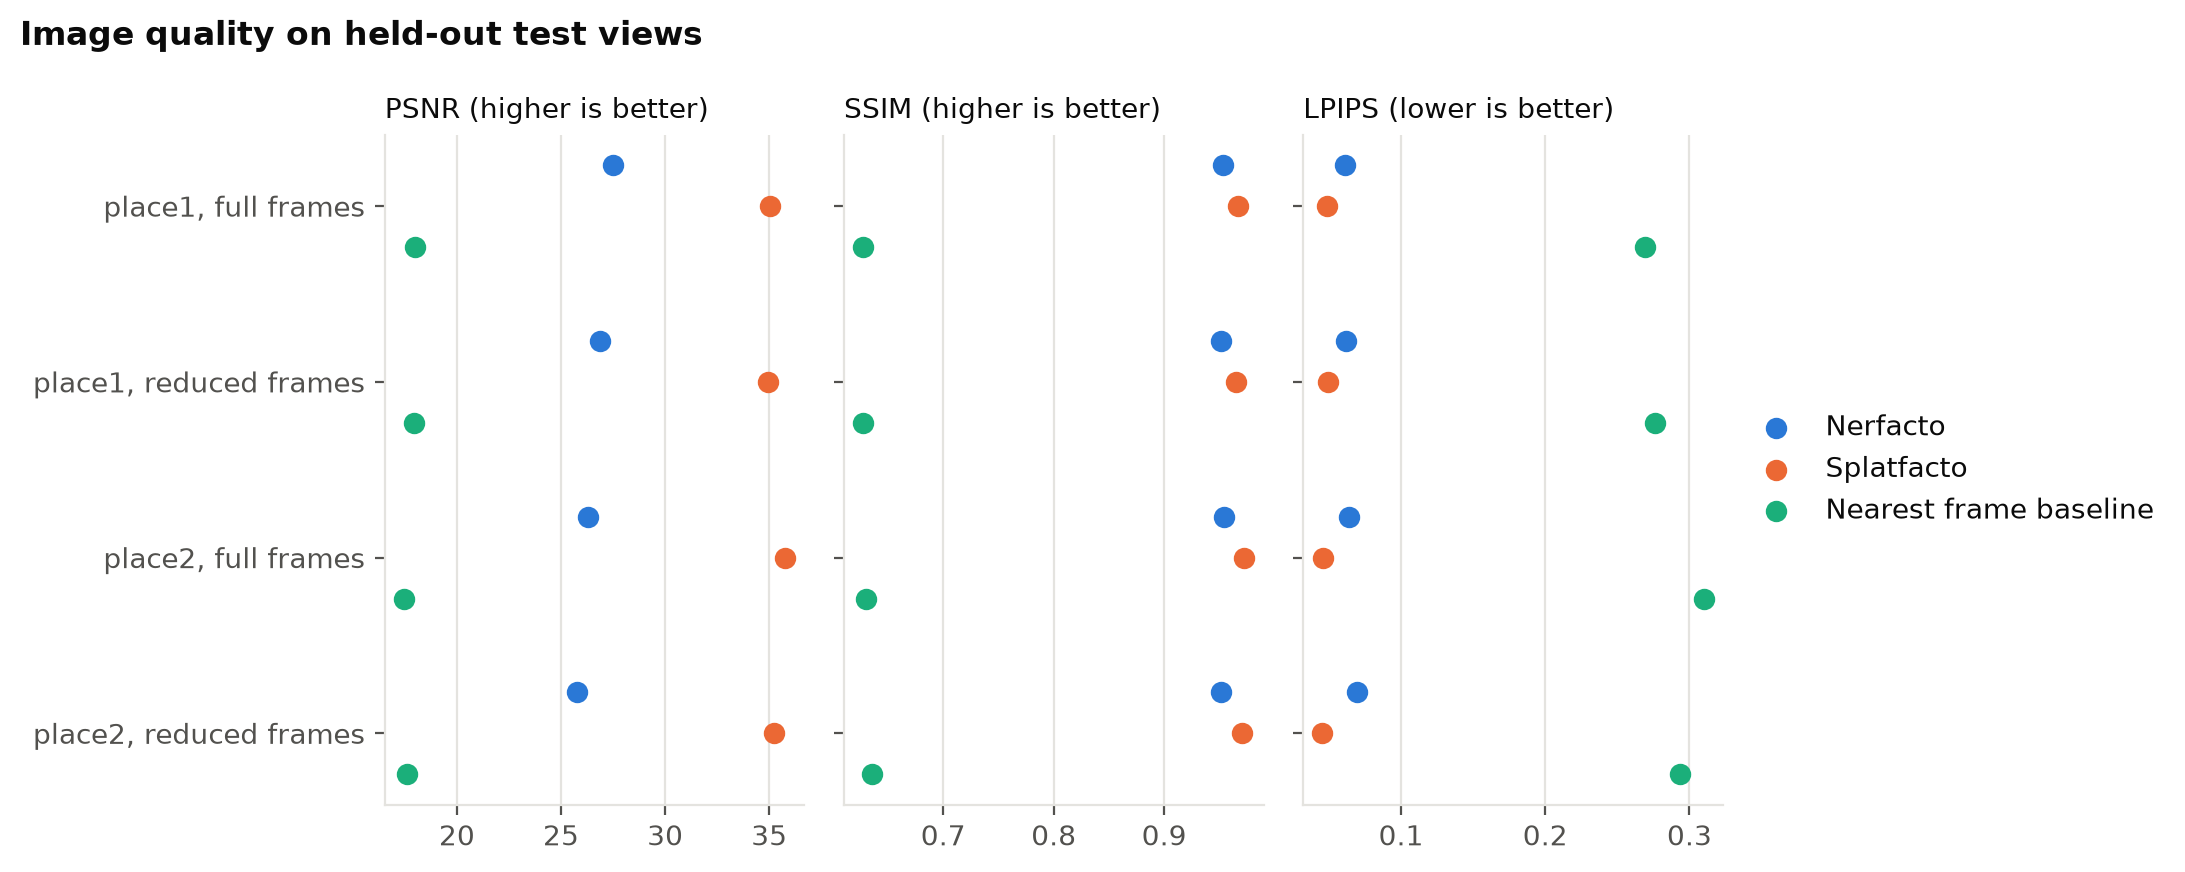

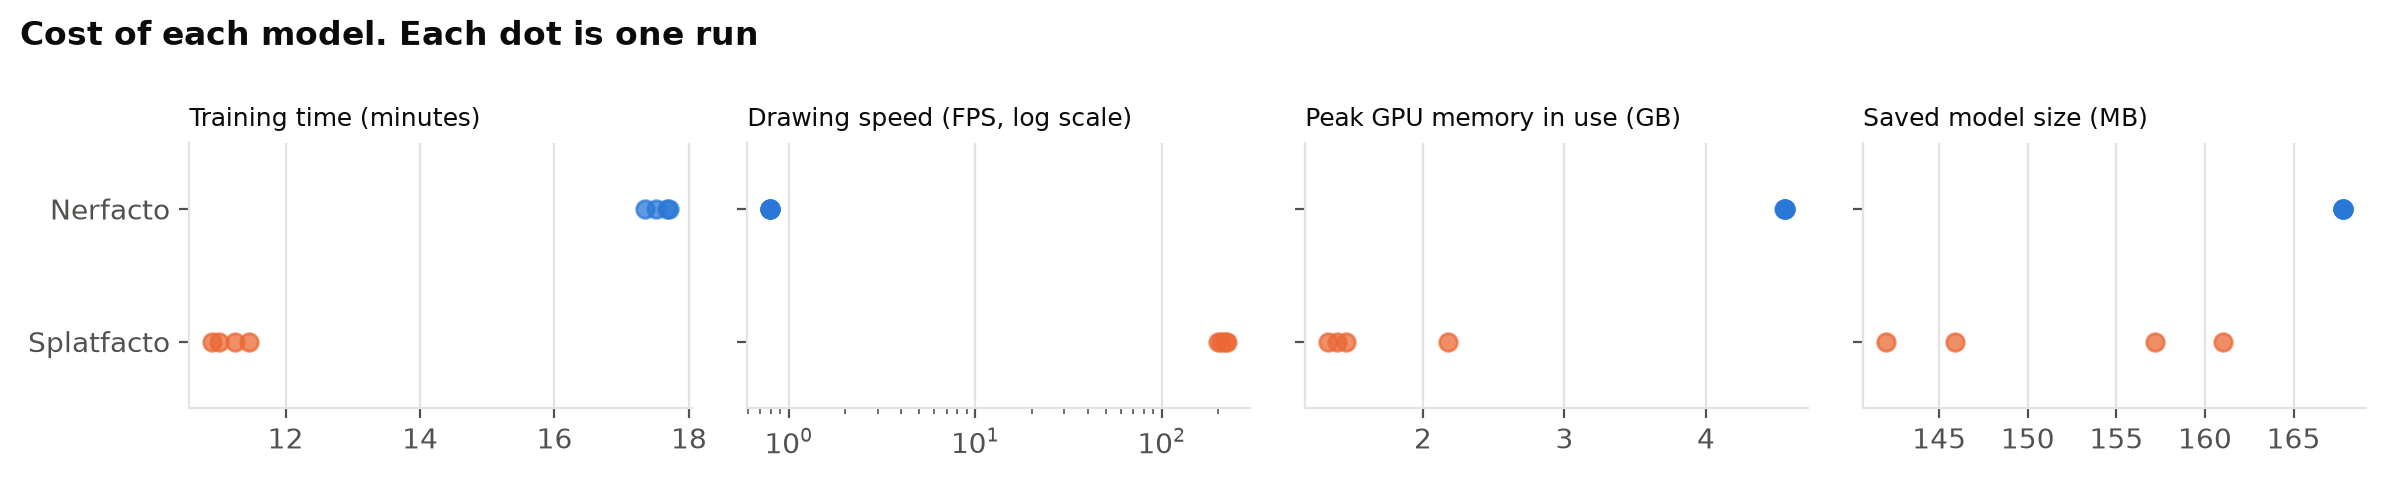

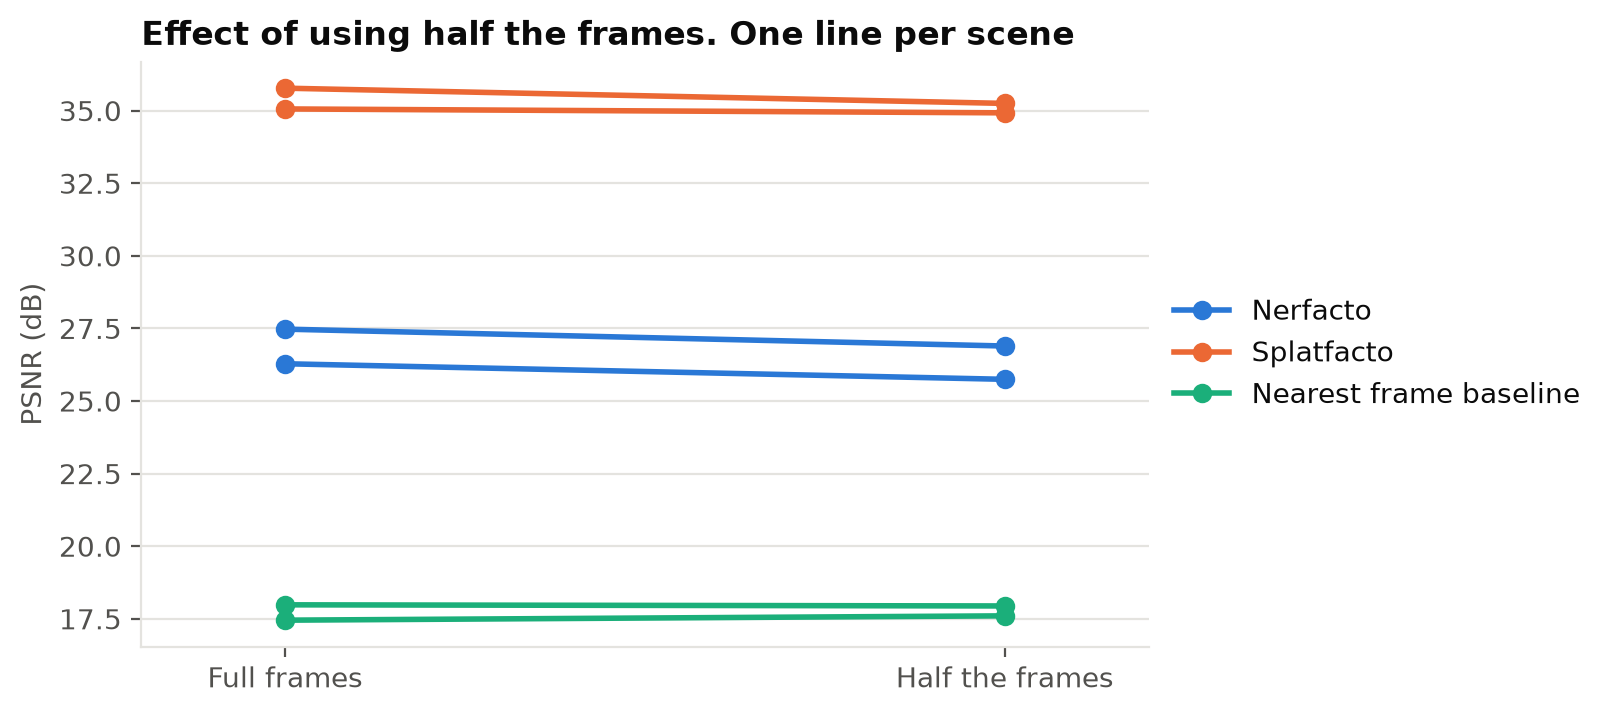

In [20]:
figures = RESULTS_DIR / "figures"
figures.mkdir(exist_ok=True)

table = pd.read_csv(RESULTS_DIR / "metrics.csv")
table = table[table["status"] == "done"]
chart_quality(table, figures)
chart_costs(table, figures)
chart_fewer_frames(table, figures)

# Show each saved chart here in the notebook.
for chart in sorted(figures.glob("fig*.png")):
    display(ShowImage(filename=str(chart), width=800))

## 6. Blind rating

PSNR, SSIM and LPIPS can't fully say what looks real, which Week 8 calls a non-verifiable question. This section
builds side-by-side images from the same test views: the real photo, then the two model outputs in random order as
View X and View Y. You can't see which is which, so your rating is less likely to favour either model.

Rate each image from 1 to 5 in `results/rating/rating_sheet.csv`, then repeat at least 24 hours later without
looking at your first ratings. Open `rating_key.csv` only after both rounds, then set `RATINGS_DONE = True`.

In [21]:
OUTPUT = RESULTS_DIR / "rating"
VIEWS_PER_SCENE = 5


def split_render(path: Path) -> tuple[Image.Image, Image.Image]:
    """Nerfstudio saves the real view and the model's view side by side. Separate them."""
    combined = Image.open(path).convert("RGB")
    width, height = combined.size
    return combined.crop((0, 0, width // 2, height)), combined.crop((width // 2, 0, width, height))


def build_panel(truth: Image.Image, first: Image.Image, second: Image.Image) -> Image.Image:
    """Place three equal images in a row, each with a label above it."""
    width, height = truth.size
    panel = Image.new("RGB", (width * 3, height + 24), "white")
    draw = ImageDraw.Draw(panel)
    for index, (image, label) in enumerate([(truth, "Real photo"), (first, "View X"), (second, "View Y")]):
        panel.paste(image, (index * width, 24))
        draw.text((index * width + 6, 6), label, fill="black")
    return panel

In [22]:
def make_rating_sheet() -> None:
    """Build the blind comparison images, unless the rating sheet already exists."""
    # A sheet that already exists may hold your ratings, so it is never replaced.
    if (OUTPUT / "rating_sheet.csv").exists():
        print(f"Keeping the existing rating sheet in {OUTPUT}")
        return
    OUTPUT.mkdir(parents=True, exist_ok=True)
    scenes = sorted({path.name.split("__")[0] for path in RENDERS.glob("*__nerfacto__full")})
    rng = random.Random(8410)  # A fixed seed keeps the order the same if this runs again.
    sheet, key = [], []

    for scene in scenes:
        files = {model: sorted((RENDERS / f"{scene}__{model}__full").glob("eval_img_*.png")) for model in MODELS}
        # Spread the views evenly across the test frames.
        step = max(len(files["nerfacto"]) // VIEWS_PER_SCENE, 1)
        for number, (nerfacto, splatfacto) in enumerate(zip(files["nerfacto"][::step], files["splatfacto"][::step])):
            if number == VIEWS_PER_SCENE:
                break
            truth, nerfacto_view = split_render(nerfacto)
            _, splatfacto_view = split_render(splatfacto)
            order = [("nerfacto", nerfacto_view), ("splatfacto", splatfacto_view)]
            rng.shuffle(order)
            name = f"{scene}_view{number + 1}.png"
            build_panel(truth, order[0][1], order[1][1]).save(OUTPUT / name)
            sheet.append({"image": name, "round1_view_x": "", "round1_view_y": "", "round2_view_x": "", "round2_view_y": ""})
            key.append({"image": name, "view_x": order[0][0], "view_y": order[1][0]})

    for filename, rows in [("rating_sheet.csv", sheet), ("rating_key.csv", key)]:
        with (OUTPUT / filename).open("w", newline="", encoding="utf-8") as file:
            writer = csv.DictWriter(file, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
    print(f"Made {len(sheet)} comparison images in {OUTPUT}")

In [23]:
make_rating_sheet()

Made 10 comparison images in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair3_virtual_tours\results\rating


In [24]:
def rating_results() -> pd.DataFrame:
    """Match the blind ratings to each model, and show how far the two rounds agree."""
    sheet = pd.read_csv(OUTPUT / "rating_sheet.csv").merge(pd.read_csv(OUTPUT / "rating_key.csv"), on="image")
    rows = []
    # Each image has a View X and a View Y, so each one becomes a row for its model.
    for view in ["x", "y"]:
        for item in sheet.itertuples():
            rows.append(
                {
                    "image": item.image,
                    "model": getattr(item, f"view_{view}"),
                    "round1": getattr(item, f"round1_view_{view}"),
                    "round2": getattr(item, f"round2_view_{view}"),
                }
            )
    ratings = pd.DataFrame(rows)
    ratings["mean_rating"] = (ratings["round1"] + ratings["round2"]) / 2
    ratings.to_csv(RESULTS_DIR / "ratings_by_model.csv", index=False)

    # Rating twice shows whether one person's judgement is stable.
    print(f"Rounds matched exactly on {(ratings['round1'] == ratings['round2']).mean():.0%} of ratings.")
    print(f"Correlation between the two rounds: {ratings['round1'].corr(ratings['round2']):.2f}")
    return ratings.groupby("model")[["round1", "round2", "mean_rating"]].mean().round(2)

In [25]:
if RATINGS_DONE:
    display(rating_results())
else:
    print("Set RATINGS_DONE to True after both rating rounds.")

Set RATINGS_DONE to True after both rating rounds.


## 7. Input-to-output demo

The input is a phone video. The output is a 3D model that draws views the camera never kept. The first image shows
a real held-out frame beside both models' views, using the first test view of each scene in random order. The
videos are walkthroughs drawn by each model from the full data.

place1_view1.png


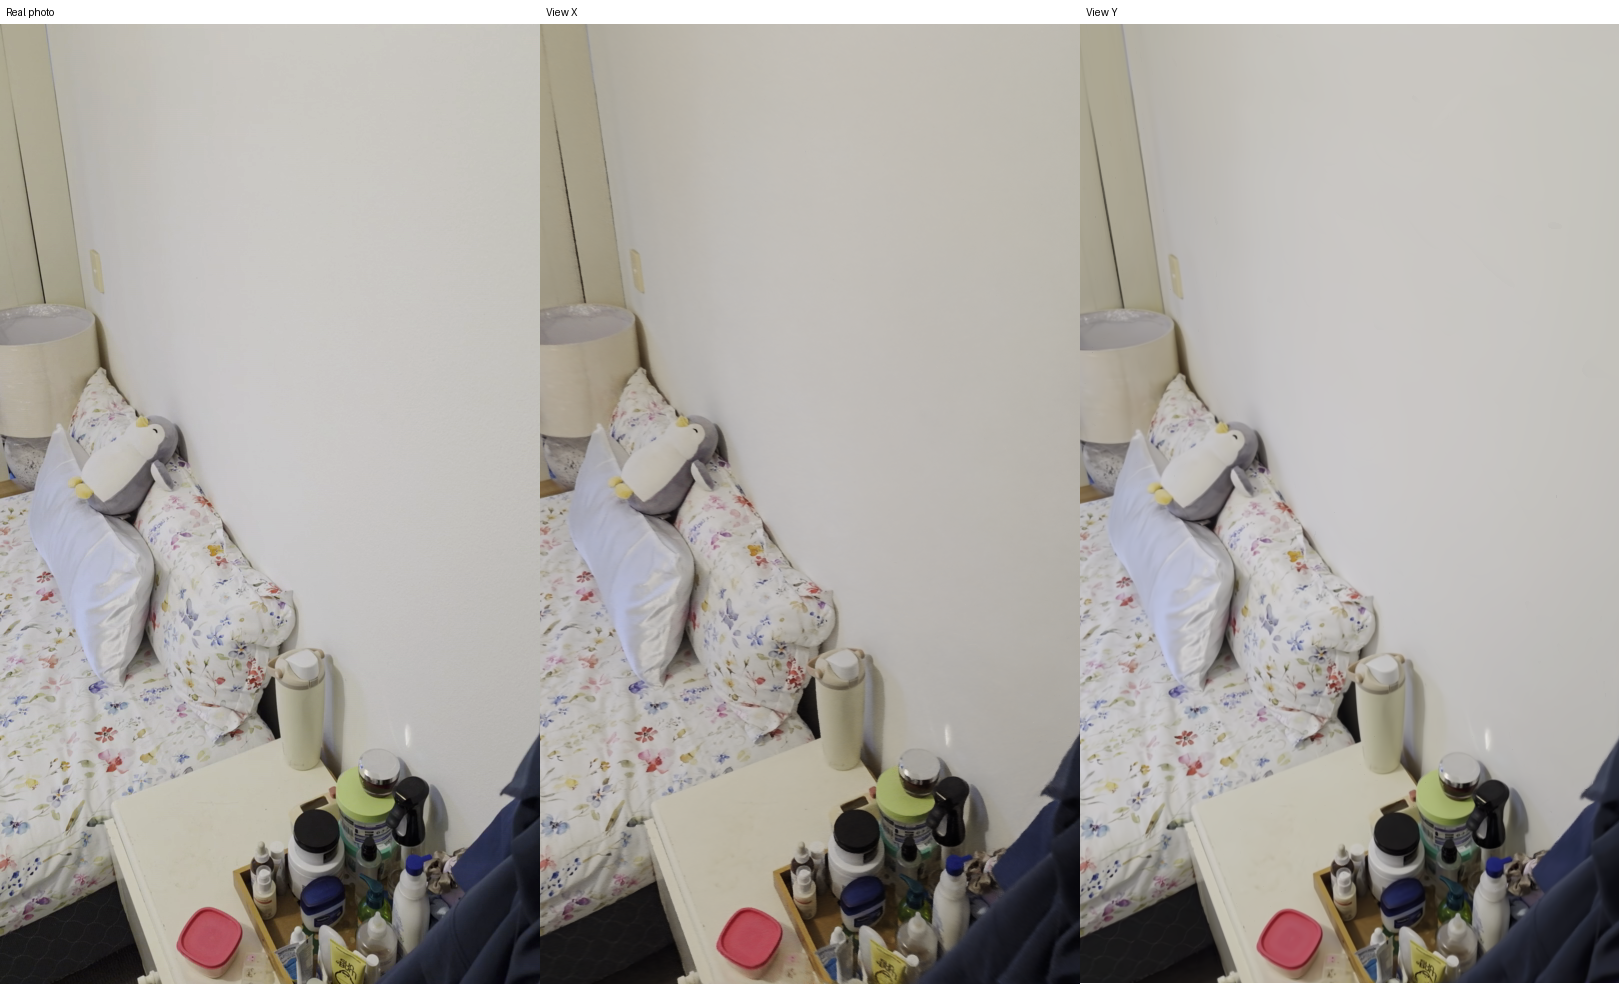

place2_view1.png


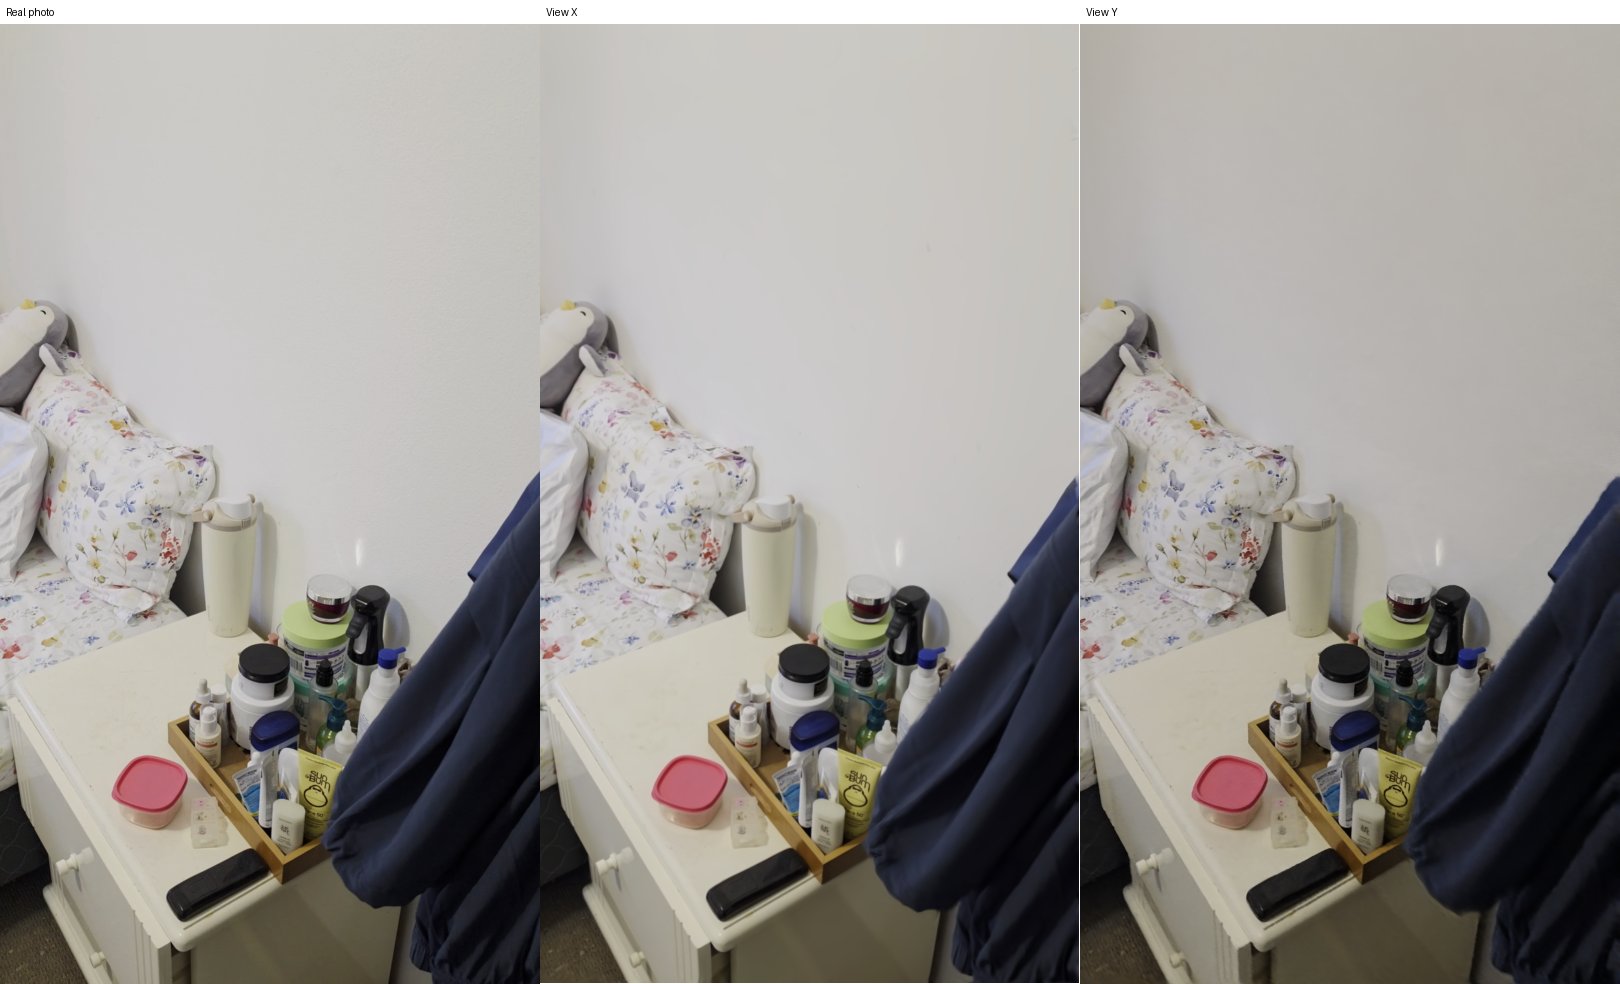

place1__nerfacto__full.mp4


place1__splatfacto__full.mp4


place2__nerfacto__full.mp4


place2__splatfacto__full.mp4


In [26]:
# One blind panel per scene, showing the real view and both model outputs.
for panel in sorted((RESULTS_DIR / "rating").glob("*_view1.png")):
    print(panel.name)
    display(ShowImage(filename=str(panel), width=800))

# The walkthroughs stay as separate files, which keeps this notebook small.
for video in sorted((RESULTS_DIR / "videos").glob("*.mp4")):
    print(video.name)
    display(Video(str(video.relative_to(HERE)), embed=False, width=320))